# Demo docente · Bicicletas compartidas
**Laboratorio de Modelado** · Regresión lineal y logística → ensembles → métricas → validación cruzada → GridSearchCV

Dataset: `datasets/bicicletas.csv` (1 000 registros horarios, datos sintéticos). Un solo dataset, **dos preguntas**:
1. ¿**Cuántas** bicicletas se alquilarán? → regresión (`alquileres`).
2. ¿Habrá **alta demanda**? → clasificación (`alta_demanda`).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay, log_loss)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Carga y exploración de datos
Primero miramos qué tenemos: filas, columnas, tipos, **valores faltantes** y cómo se distribuyen las variables.

In [ ]:
RUTA = Path("/content/bicicletas.csv")
if not RUTA.exists():            # por si subís el CSV directo a Colab
    RUTA = Path("bicicletas.csv")
df = pd.read_csv(RUTA)
display(df.head())
df.info()
display(df.describe().T.round(2))
print("Valores faltantes por columna:\n", df.isna().sum()[df.isna().sum() > 0])

,temperatura,humedad,viento,lluvia,hora_pico,fin_de_semana,alquileres,alta_demanda
0,22.1,59.1,7.8,0,0,0,92,0
1,12.7,49.1,14.4,1,0,0,20,0
2,25.3,53.8,10.2,0,1,0,153,1
3,26.6,69.5,22.1,0,1,1,136,1
4,6.3,60.0,3.9,0,0,0,39,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperatura    1000 non-null   float64
 1   humedad        975 non-null    float64
 2   viento         1000 non-null   float64
 3   lluvia         1000 non-null   int64  
 4   hora_pico      1000 non-null   int64  
 5   fin_de_semana  1000 non-null   int64  
 6   alquileres     1000 non-null   int64  
 7   alta_demanda   1000 non-null   int64  
dtypes: float64(3), int64(5)
memory usage: 62.6 KB


,count,mean,std,min,25%,50%,75%,max
temperatura,1000.0,19.80,6.92,-5.5,15.10,20.0,24.1,42.3
humedad,975.0,58.78,15.25,15.0,49.00,59.3,69.0,100.0
viento,1000.0,12.87,8.14,0.5,6.90,11.5,16.8,52.6
lluvia,1000.0,0.18,0.38,0.0,0.00,0.0,0.0,1.0
hora_pico,1000.0,0.32,0.47,0.0,0.00,0.0,1.0,1.0
fin_de_semana,1000.0,0.28,0.45,0.0,0.00,0.0,1.0,1.0
alquileres,1000.0,89.36,44.24,0.0,60.75,84.0,118.0,402.0
alta_demanda,1000.0,0.30,0.46,0.0,0.00,0.0,1.0,1.0


Valores faltantes por columna:
 humedad    25
dtype: int64


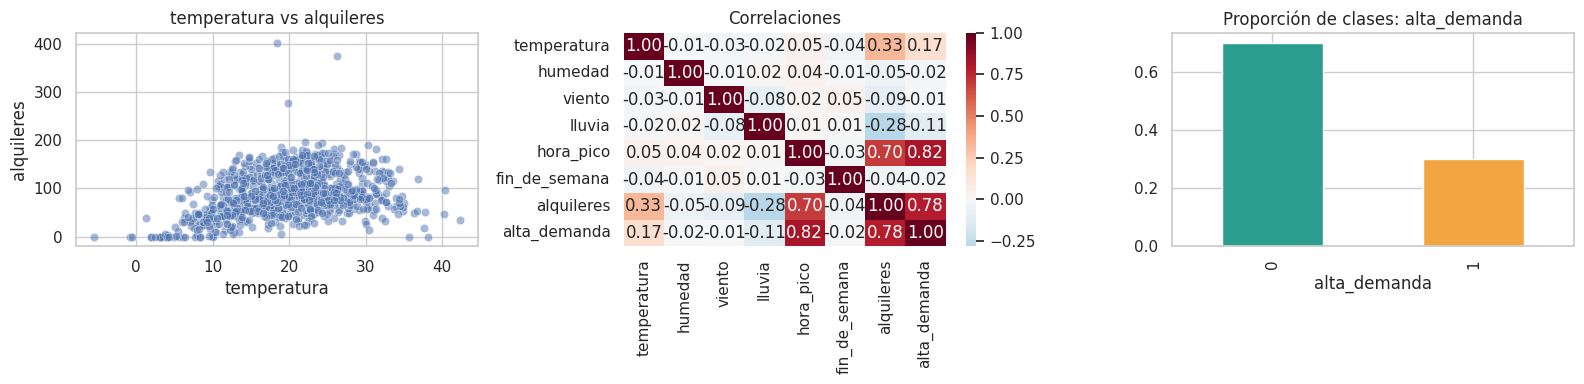

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="temperatura", y="alquileres", alpha=.5, ax=ax[0]); ax[0].set_title("temperatura vs alquileres")
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Correlaciones")
df["alta_demanda"].value_counts(normalize=True).plot.bar(ax=ax[2], color=["#2A9D8F", "#F2A541"]); ax[2].set_title("Proporción de clases: alta_demanda")
plt.tight_layout(); plt.show()

## 2. Variables independientes (X), dependientes (y) y partición Train/Test
Tenemos **dos preguntas** sobre el mismo dataset:
- **Regresión** → ¿cuánto? → `alquileres` (continua, en alquileres por hora).
- **Clasificación** → ¿sí o no? → `alta_demanda` (binaria: alta demanda (≥ percentil 70 de alquileres)).

Separamos un 20 % para el **test final** ("cofre bajo llave"). Con `stratify` conservamos la proporción de clases.

In [ ]:
X = df.drop(columns=["alquileres", "alta_demanda"])
y_reg, y_clf = df["alquileres"], df["alta_demanda"]
X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de clase positiva en train / test:", round(yc_train.mean(), 3), "/", round(yc_test.mean(), 3))

Train: (800, 6) | Test: (200, 6)
Proporción de clase positiva en train / test: 0.3 / 0.3


## 3. Regresión lineal: predecir un número
$\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$

Usamos un **Pipeline** para encadenar *imputar → escalar → modelo*. Así el escalador y el imputador se ajustan **solo con train** (evita *data leakage*).

Intercepto (β0): 89.87


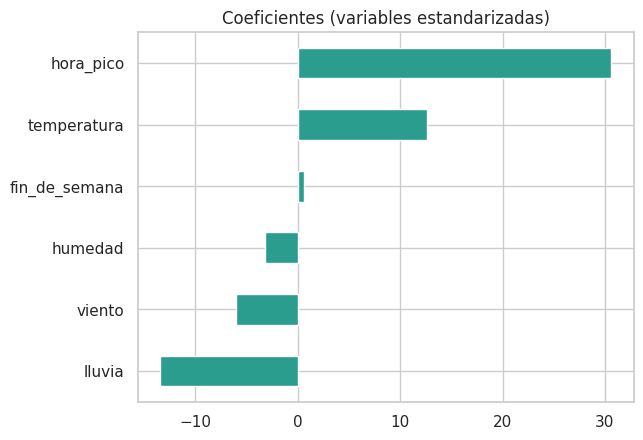

In [ ]:
reg = Pipeline([("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("modelo", LinearRegression())])
reg.fit(X_train, yr_train)
pred = reg.predict(X_test)
coefs = pd.Series(reg.named_steps["modelo"].coef_, index=X.columns).sort_values()
print("Intercepto (β0):", round(reg.named_steps["modelo"].intercept_, 2))
coefs.plot.barh(title="Coeficientes (variables estandarizadas)", color="#2A9D8F"); plt.show()

MAE=15.19 | MSE=396.66 | RMSE=19.92 | R²=0.754


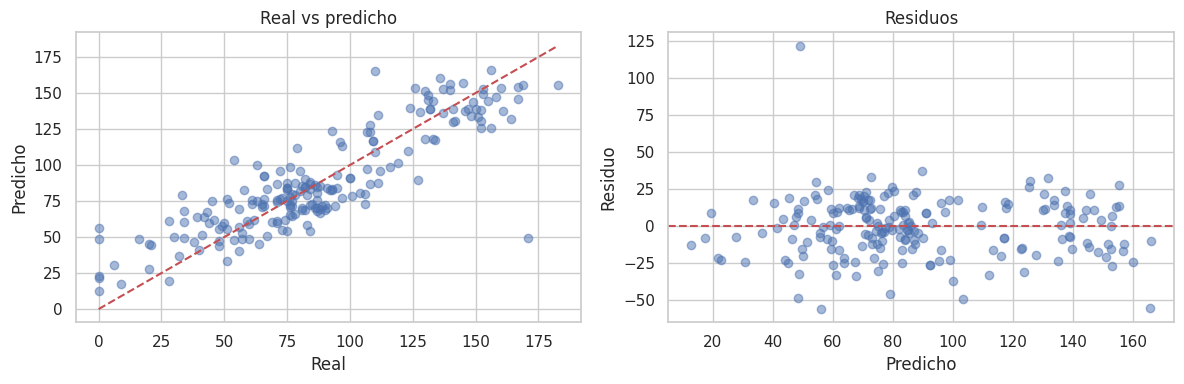

In [ ]:
mae = mean_absolute_error(yr_test, pred)
mse = mean_squared_error(yr_test, pred)
print(f"MAE={mae:.2f} | MSE={mse:.2f} | RMSE={np.sqrt(mse):.2f} | R²={r2_score(yr_test, pred):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lim = [yr_test.min(), yr_test.max()]
ax[0].scatter(yr_test, pred, alpha=.5); ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="Real", ylabel="Predicho", title="Real vs predicho")
ax[1].scatter(pred, yr_test - pred, alpha=.5); ax[1].axhline(0, color="r", ls="--"); ax[1].set(xlabel="Predicho", ylabel="Residuo", title="Residuos")
plt.tight_layout(); plt.show()

## 4. ¿Cómo aprende? Descenso del gradiente "a mano"
Regresión simple con **una** variable estandarizada. Repetimos: predecir → medir el error (MSE) → mover $\beta_0,\beta_1$ en la dirección que baja la pérdida. `lr` es la **tasa de aprendizaje** (un hiperparámetro).

Descenso del gradiente: β0=89.36  β1=14.74  | MSE final=1738.0
scikit-learn          : β0=89.36  β1=14.74


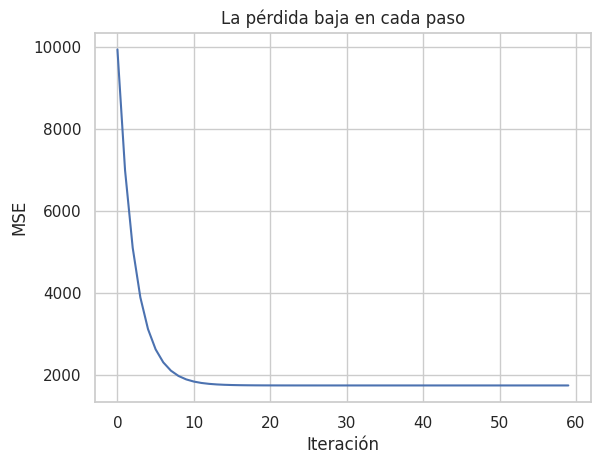

In [ ]:
d = df[["temperatura", "alquileres"]].dropna()
x = ((d["temperatura"] - d["temperatura"].mean()) / d["temperatura"].std()).values
t = d["alquileres"].values
b0, b1, lr, hist = 0.0, 0.0, 0.1, []
for epoch in range(60):
    err = (b0 + b1 * x) - t
    hist.append(np.mean(err ** 2))            # pérdida: MSE
    b0 -= lr * 2 * err.mean()                 # gradiente respecto de β0
    b1 -= lr * 2 * (err * x).mean()           # gradiente respecto de β1
chk = LinearRegression().fit(x.reshape(-1, 1), t)
print(f"Descenso del gradiente: β0={b0:.2f}  β1={b1:.2f}  | MSE final={hist[-1]:.1f}")
print(f"scikit-learn          : β0={chk.intercept_:.2f}  β1={chk.coef_[0]:.2f}")
plt.plot(hist); plt.xlabel("Iteración"); plt.ylabel("MSE"); plt.title("La pérdida baja en cada paso"); plt.show()

## 5. Regresión logística: predecir una probabilidad
$p = \dfrac{1}{1+e^{-z}}$ con $z = \beta_0 + \beta_1 x_1 + \dots$ (función **sigmoide**). Pasamos de probabilidad a clase con un **umbral** (por defecto 0.5).

Primeras 8 probabilidades: [0.   0.02 0.06 0.   0.84 0.08 0.3  0.01]


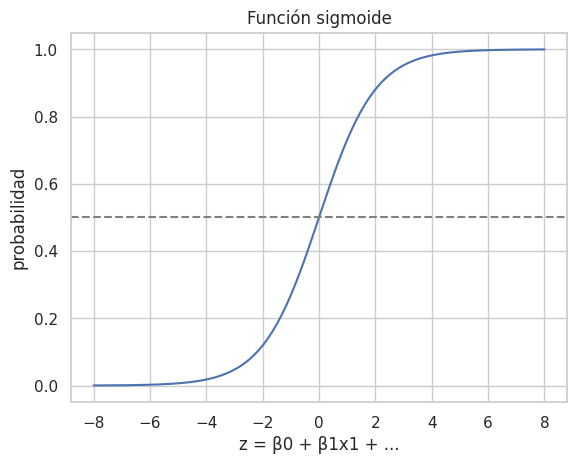

In [ ]:
clf_log = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("modelo", LogisticRegression(max_iter=1000))])
clf_log.fit(X_train, yc_train)
proba = clf_log.predict_proba(X_test)[:, 1]
print("Primeras 8 probabilidades:", proba[:8].round(2))
z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z))); plt.axhline(.5, color="gray", ls="--")
plt.title("Función sigmoide"); plt.xlabel("z = β0 + β1x1 + ..."); plt.ylabel("probabilidad"); plt.show()

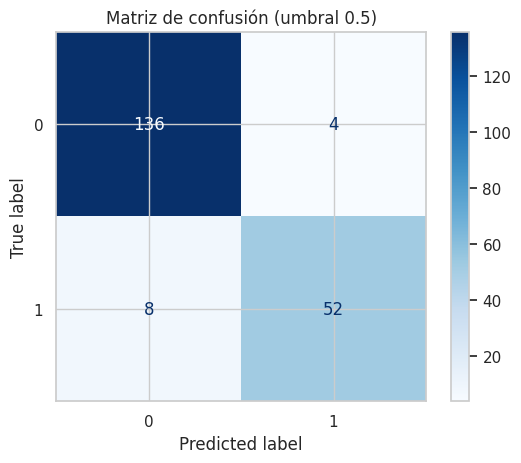

              precision    recall  f1-score   support

           0      0.944     0.971     0.958       140
           1      0.929     0.867     0.897        60

    accuracy                          0.940       200
   macro avg      0.937     0.919     0.927       200
weighted avg      0.940     0.940     0.939       200

AUC: 0.973 | Log Loss: 0.172
Accuracy de un modelo 'tonto' que siempre dice 0: 0.7


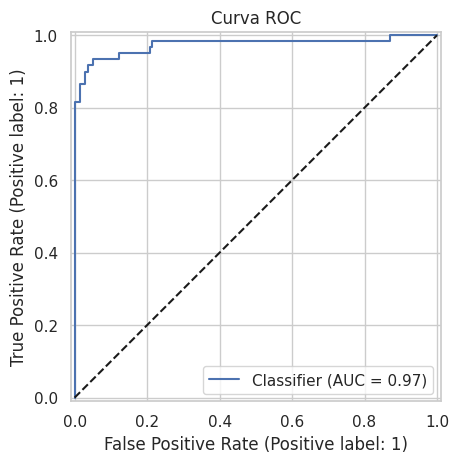

In [ ]:
y_pred = (proba >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(yc_test, y_pred, cmap="Blues"); plt.title("Matriz de confusión (umbral 0.5)"); plt.show()
print(classification_report(yc_test, y_pred, digits=3))
print("AUC:", round(roc_auc_score(yc_test, proba), 3), "| Log Loss:", round(log_loss(yc_test, proba), 3))
print("Accuracy de un modelo 'tonto' que siempre dice 0:", round((yc_test == 0).mean(), 3))
RocCurveDisplay.from_predictions(yc_test, proba); plt.plot([0, 1], [0, 1], "k--"); plt.title("Curva ROC"); plt.show()

### Efecto del umbral
Bajar el umbral atrapa más positivos (sube el **recall**) pero genera más falsas alarmas (baja la **precisión**).

In [ ]:
rows = []
for thr in [0.1, 0.2, 0.3, 0.5, 0.7]:
    yp = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yc_test, yp).ravel()
    rows.append(dict(umbral=thr, TP=tp, FP=fp, FN=fn, TN=tn,
                     precision=tp / (tp + fp) if tp + fp else np.nan, recall=tp / (tp + fn)))
display(pd.DataFrame(rows).round(3))

,umbral,TP,FP,FN,TN,precision,recall
0,0.1,56,15,4,125,0.789,0.933
1,0.2,55,6,5,134,0.902,0.917
2,0.3,54,5,6,135,0.915,0.900
3,0.5,52,4,8,136,0.929,0.867
4,0.7,49,2,11,138,0.961,0.817


## 6. Ensembles: Bagging, Boosting y Stacking
- **Bagging** (Random Forest): muchos árboles independientes → baja la *varianza*.
- **Boosting** (Gradient Boosting): árboles secuenciales que corrigen errores → baja el *sesgo*.
- **Stacking**: modelos de familias distintas + un meta-modelo que decide.

In [ ]:
imp = lambda: SimpleImputer(strategy="median")
modelos = {
    "LogReg": clf_log,
    "RandomForest (bagging)": Pipeline([("imp", imp()), ("m", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
    "GradientBoosting (boosting)": Pipeline([("imp", imp()), ("m", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    "Stacking": Pipeline([("imp", imp()), ("m", StackingClassifier(
        estimators=[("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
                    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier())),
                    ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))],
        final_estimator=LogisticRegression(max_iter=1000)))]),
}
print("Modelos a comparar:", list(modelos))

Modelos a comparar: ['LogReg', 'RandomForest (bagging)', 'GradientBoosting (boosting)', 'Stacking']


## 7. Validación cruzada estratificada
Evaluamos cada modelo con **5 folds** sobre el set de *train* (el test sigue intacto). Miramos el **promedio** y la **desviación**: un buen modelo tiene promedio alto y desvío bajo.

,F1 medio,Desvío
LogReg,0.893,0.023
RandomForest (bagging),0.889,0.025
GradientBoosting (boosting),0.888,0.029
Stacking,0.896,0.021


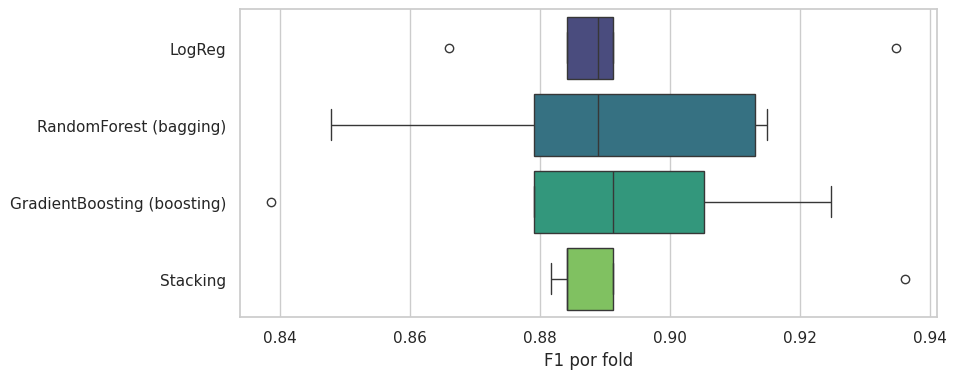

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
res = {nombre: cross_val_score(m, X_train, yc_train, cv=cv, scoring="f1") for nombre, m in modelos.items()}
resumen = pd.DataFrame({k: {"F1 medio": v.mean(), "Desvío": v.std()} for k, v in res.items()}).T.round(3)
display(resumen)
plt.figure(figsize=(9, 4)); sns.boxplot(data=pd.DataFrame(res), orient="h", palette="viridis")
plt.xlabel("F1 por fold"); plt.show()

## 8. Ajuste de hiperparámetros con GridSearchCV
Probamos **todas las combinaciones** de una grilla; cada una se evalúa con validación cruzada.

In [ ]:
pipe_rf = Pipeline([("imp", imp()), ("m", RandomForestClassifier(random_state=RANDOM_STATE))])
param_grid = {"m__n_estimators": [100, 300],
              "m__max_depth": [3, 6, None],
              "m__min_samples_leaf": [1, 5]}
gs = GridSearchCV(pipe_rf, param_grid, cv=cv, scoring="f1", n_jobs=-1)
gs.fit(X_train, yc_train)
print("Combinaciones:", len(gs.cv_results_["params"]), "x 5 folds =", len(gs.cv_results_["params"]) * 5, "entrenamientos")
print("best_params_:", gs.best_params_)
print("best_score_ :", round(gs.best_score_, 3))
display(pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5).round(3))

Combinaciones: 12 x 5 folds = 60 entrenamientos
best_params_: {'m__max_depth': None, 'm__min_samples_leaf': 5, 'm__n_estimators': 300}
best_score_ : 0.903


,params,mean_test_score,std_test_score
11,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.903,0.020
10,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.901,0.022
7,"{'m__max_depth': 6, 'm__min_samples_leaf': 5, ...",0.899,0.024
2,"{'m__max_depth': 3, 'm__min_samples_leaf': 5, ...",0.899,0.019
6,"{'m__max_depth': 6, 'm__min_samples_leaf': 5, ...",0.896,0.027


## 9. Evaluación final: se abre el "cofre" **una sola vez**
Usamos `best_estimator_` (ya reentrenado con todo el train) y lo probamos contra el test que nunca vio.

              precision    recall  f1-score   support

           0      0.933     0.993     0.962       140
           1      0.980     0.833     0.901        60

    accuracy                          0.945       200
   macro avg      0.957     0.913     0.931       200
weighted avg      0.947     0.945     0.944       200

AUC en test: 0.979


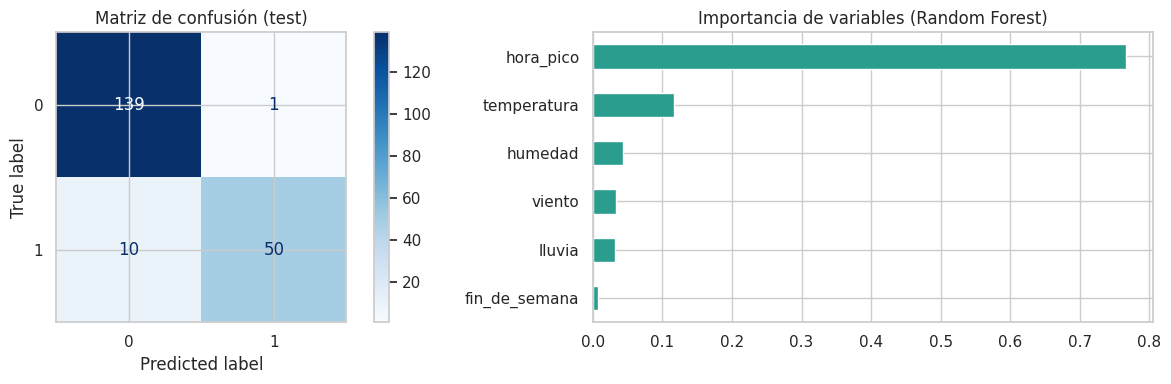

In [ ]:
mejor = gs.best_estimator_
yp = mejor.predict(X_test); pp = mejor.predict_proba(X_test)[:, 1]
print(classification_report(yc_test, yp, digits=3))
print("AUC en test:", round(roc_auc_score(yc_test, pp), 3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ConfusionMatrixDisplay.from_predictions(yc_test, yp, cmap="Blues", ax=ax[0]); ax[0].set_title("Matriz de confusión (test)")
pd.Series(mejor.named_steps["m"].feature_importances_, index=X.columns).sort_values().plot.barh(ax=ax[1], color="#2A9D8F")
ax[1].set_title("Importancia de variables (Random Forest)"); plt.tight_layout(); plt.show()